In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout

In [ ]:
df = pd.read_csv("stock_data.csv")

df.head()   

,Unnamed: 0,Stock_1,Stock_2,Stock_3,Stock_4,Stock_5
0,01/01/2020,101.764052,100.160928,99.494642,99.909756,101.761266
1,02/01/2020,102.171268,99.969968,98.682973,100.640755,102.528643
2,03/01/2020,103.171258,99.575237,98.182139,100.574847,101.887811
3,04/01/2020,105.483215,99.308641,97.149381,100.925017,101.490049
4,05/01/2020,107.453176,98.188428,99.575396,101.594411,101.604283


In [15]:
print("Shape:", df.shape)

print("\nColumns:")
print(df.columns)

print("\nMissing values:")
print(df.isnull().sum())

Shape: (365, 6)

Columns:
Index(['Unnamed: 0', 'Stock_1', 'Stock_2', 'Stock_3', 'Stock_4', 'Stock_5'], dtype='str')

Missing values:
Unnamed: 0    0
Stock_1       0
Stock_2       0
Stock_3       0
Stock_4       0
Stock_5       0
dtype: int64


In [17]:
# Convert the date column safely
df['Date'] = pd.to_datetime(
    df['Unnamed: 0'],
    format='mixed',
    errors='coerce'
)

# Remove the old column
df = df.drop('Unnamed: 0', axis=1)

# Display first 5 rows
df.head()

,Stock_1,Stock_2,Stock_3,Stock_4,Stock_5,Date
0,101.764052,100.160928,99.494642,99.909756,101.761266,2020-01-01
1,102.171268,99.969968,98.682973,100.640755,102.528643,2020-02-01
2,103.171258,99.575237,98.182139,100.574847,101.887811,2020-03-01
3,105.483215,99.308641,97.149381,100.925017,101.490049,2020-04-01
4,107.453176,98.188428,99.575396,101.594411,101.604283,2020-05-01


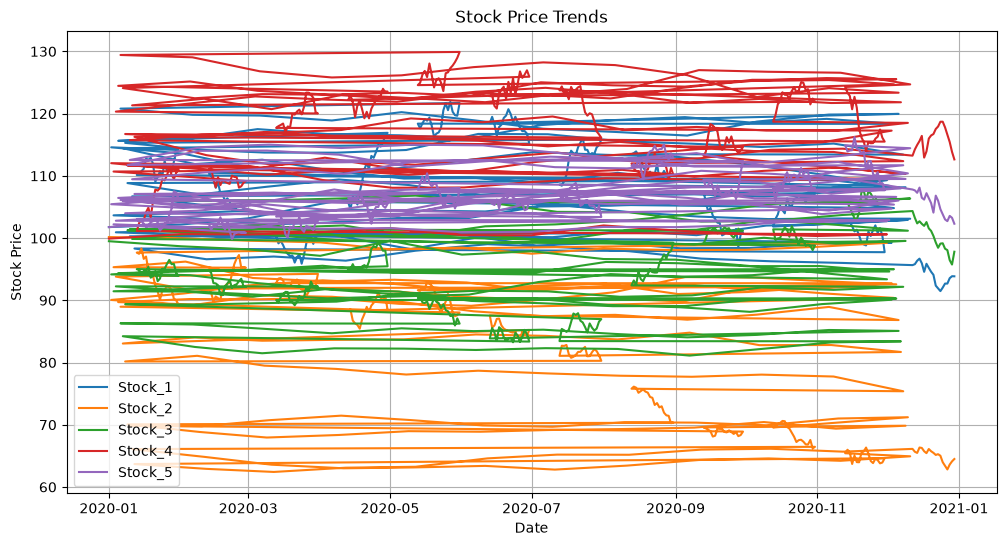

In [18]:
plt.figure(figsize=(12, 6))

for column in ['Stock_1', 'Stock_2', 'Stock_3', 'Stock_4', 'Stock_5']:
    plt.plot(df['Date'], df[column], label=column)

plt.title("Stock Price Trends")
plt.xlabel("Date")
plt.ylabel("Stock Price")
plt.legend()
plt.grid()
plt.show()

In [19]:
data = df[['Stock_1']].values

print(data[:10])

[[101.7640523]
 [102.1712685]
 [103.1712576]
 [105.4832152]
 [107.4531755]
 [106.4030593]
 [107.4139825]
 [107.2514037]
 [107.1407   ]
 [107.5806181]]


In [ ]:
#Days 1–30
# ↓
#LSTM
#  ↓
# Day 31 prediction

In [20]:
scaler = MinMaxScaler(feature_range=(0, 1))

scaled_data = scaler.fit_transform(data)

print(scaled_data[:10])

[[0.33817   ]
 [0.35155324]
 [0.38441807]
 [0.46040099]
 [0.52514411]
 [0.49063184]
 [0.52385602]
 [0.51851284]
 [0.51487454]
 [0.52933253]]


In [21]:
sequence_length = 30

X = []
y = []

for i in range(sequence_length, len(scaled_data)):
    X.append(scaled_data[i-sequence_length:i, 0])
    y.append(scaled_data[i, 0])

X = np.array(X)
y = np.array(y)

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (335, 30)
y shape: (335,)


In [22]:
X = X.reshape(X.shape[0], X.shape[1], 1)

print("New X shape:", X.shape)

New X shape: (335, 30, 1)


In [23]:
train_size = int(len(X) * 0.8)

X_train = X[:train_size]
X_test = X[train_size:]

y_train = y[:train_size]
y_test = y[train_size:]

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 268
Testing samples: 67


In [24]:
model = Sequential()

model.add(
    LSTM(
        50,
        return_sequences=True,
        input_shape=(X_train.shape[1], 1)
    )
)

model.add(Dropout(0.2))

model.add(
    LSTM(50)
)

model.add(Dropout(0.2))

model.add(Dense(1))

c:\Users\Raj\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [25]:
model.compile(
    optimizer='adam',
    loss='mean_squared_error'
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 30, 50)         │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 30, 50)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 50)             │        20,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 50)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 30,651 (119.73 KB)

 Trainable params: 30,651 (119.73 KB)

 Non-trainable params: 0 (0.00 B)

In [27]:
history = model.fit(
    X_train,
    y_train,
    epochs=20,
    batch_size=16,
    validation_split=0.1,
    verbose=1
)

Epoch 1/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 3s 40ms/step - loss: 0.1293 - val_loss: 0.0066
Epoch 2/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.0248 - val_loss: 0.0109
Epoch 3/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.0191 - val_loss: 0.0052
Epoch 4/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 0.0169 - val_loss: 0.0079
Epoch 5/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 0.0153 - val_loss: 0.0040
Epoch 6/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 0.0125 - val_loss: 0.0036
Epoch 7/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.0118 - val_loss: 0.0040
Epoch 8/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 0.0122 - val_loss: 0.0046
Epoch 9/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.0117 - val_loss: 0.0029
Epoch 10/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.0093 - val_loss: 0.0029
Epoch 11/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - loss: 0.0115 - val_loss: 0.0028
Epoch 12/20
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - loss: 0.0

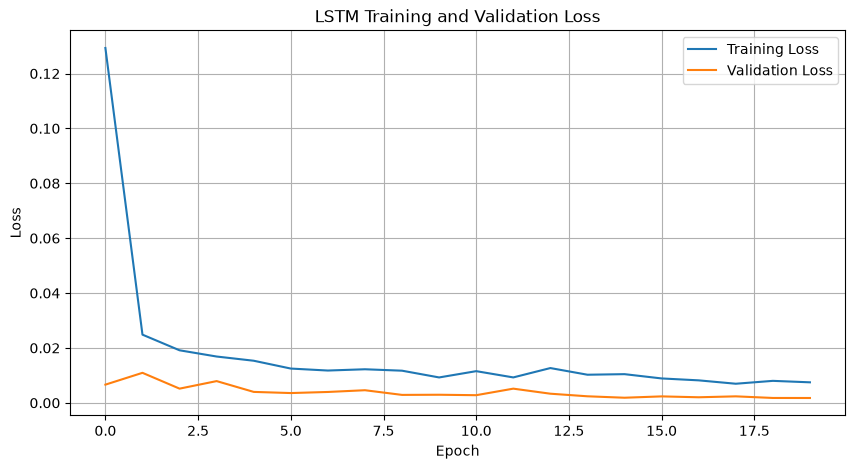

In [28]:
plt.figure(figsize=(10, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title("LSTM Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.legend()
plt.grid()

plt.show()

In [29]:
predictions = model.predict(X_test)

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 120ms/step


In [30]:
predictions = scaler.inverse_transform(predictions)

actual_prices = scaler.inverse_transform(
    y_test.reshape(-1, 1)
)

In [31]:
rmse = np.sqrt(
    mean_squared_error(
        actual_prices,
        predictions
    )
)

print("RMSE:", rmse)

RMSE: 1.9346798550544464


In [32]:
mae = mean_absolute_error(
    actual_prices,
    predictions
)

print("MAE:", mae)

MAE: 1.5806916763942986


In [33]:
comparison = pd.DataFrame({
    'Actual Price': actual_prices.flatten(),
    'Predicted Price': predictions.flatten()
})

comparison.head(10)

,Actual Price,Predicted Price
0,106.596103,106.332489
1,106.990568,106.625671
2,105.592708,106.886383
3,107.343573,107.005913
4,107.216731,107.138252
5,106.487467,107.255630
6,107.197081,107.303230
7,106.703203,107.346458
8,105.279506,107.346794
9,103.861689,107.215462


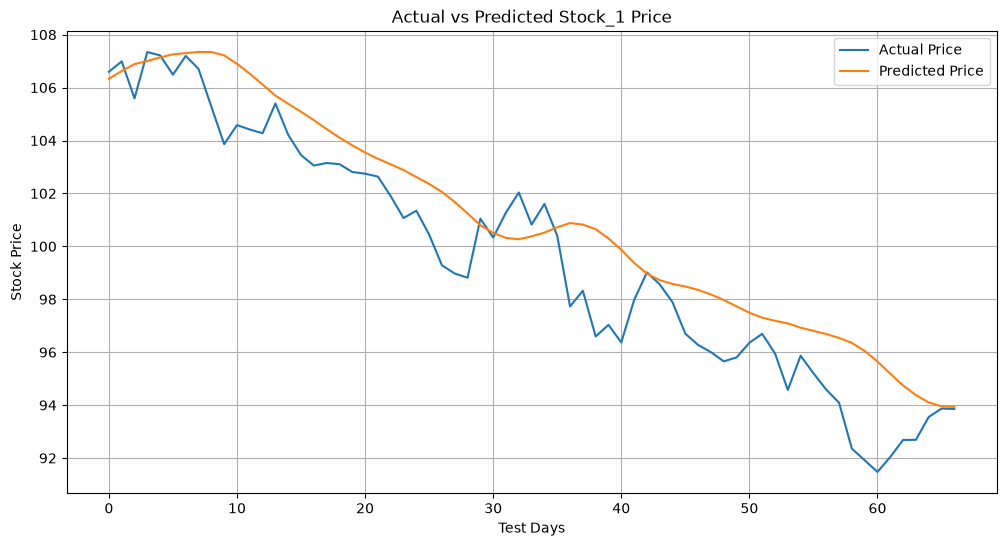

In [34]:
plt.figure(figsize=(12, 6))

plt.plot(
    actual_prices,
    label='Actual Price'
)

plt.plot(
    predictions,
    label='Predicted Price'
)

plt.title("Actual vs Predicted Stock_1 Price")
plt.xlabel("Test Days")
plt.ylabel("Stock Price")

plt.legend()
plt.grid()

plt.show()

In [35]:
last_30_days = scaled_data[-30:]

X_future = last_30_days.reshape(1, 30, 1)

next_day_scaled = model.predict(X_future)

next_day_price = scaler.inverse_transform(
    next_day_scaled
)

print(
    "Predicted Stock_1 price for next day:",
    next_day_price[0][0]
)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
Predicted Stock_1 price for next day: 94.0047
